# Paper 3 · Phase 1c — DroneDetect source baseline and interference table (RQ1, E1)

7-class identification (no Background class in DroneDetect). The source CNN is trained on **CLEAN active windows only**, split by recording
(`.dat` file), and the checkpoint is the epoch with best val macro-F1. Each model is then scored on its CLEAN test recordings and on every
BLUE / WIFI / BOTH recording. (drone, mode) pairs absent from CLEAN (Phantom 4 FY) are kept out of the interference table.

Grid:
- main: tail ∈ {default `bn7→prelu4`, linear} × 5 seeds × 5 folds;
- shortcut test: CLEAN **noise-only** windows, default tail × 5 × 5.

Per-run logits are cached in `results/paper3/phase1/runs/`, so the notebook resumes and tables re-render without retraining.

In [1]:
import os
import itertools
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import wilcoxon
from sklearn.metrics import roc_auc_score
from tqdm import tqdm

from rfml_uav.drone_detect.dataset import DRONES
from rfml_uav.eval.metrics import classification_report_dict
from rfml_uav.eval.splits import make_splits
from rfml_uav.nn.models import get_model
from rfml_uav.nn.train import train_best_val, predict_logits

load_dotenv()
base = os.path.join(os.getenv("DATA_PATH"), "results/paper3/phase1")
runs_path = os.path.join(base, "runs")
ckpt_path = os.path.join(os.getenv("DATA_PATH"), "checkpoints/paper3/phase1")
for p in (runs_path, ckpt_path):
    os.makedirs(p, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CLASSES = list(DRONES)
GROUP = {"AIR": "A", "DIS": "A", "PHA": "A", "INS": "B", "MIN": "B", "MP1": "B", "MP2": "B"}  # receiver configuration
SUBSETS = ["CLEAN", "BLUE", "WIFI", "BOTH"]
TAILS = {"default": False, "linear": True}
SEEDS, K_FOLDS = [0, 1, 2, 3, 4], 5
EPOCHS, BATCH_SIZE, LEARNING_RATE = 50, 256, 0.01

## Data

In [2]:
F = dict(np.load(os.path.join(base, "features.npz")))
F["y"] = np.array([CLASSES.index(d) for d in F["drone"]])
clean = F["subset"] == "CLEAN"
seen = {(d, m) for d, m in zip(F["drone"][clean], F["mode"][clean])}
F["seen"] = np.array([(d, m) in seen for d, m in zip(F["drone"], F["mode"])])
TARGET = np.flatnonzero(F["active"] & ~clean)  # every BLUE/WIFI/BOTH active row, incl. unseen (dropped at report time)
print({k: v.shape for k, v in F.items() if k == "X"}, "unseen (drone, mode) in targets:",
      sorted({(d, m) for d, m in zip(F["drone"][TARGET], F["mode"][TARGET]) if (d, m) not in seen}))

X_all = torch.tensor(F["X"], dtype=torch.float32, device=device).unsqueeze(1)
y_all = torch.tensor(F["y"], dtype=torch.long, device=device)
# in-band WPD nodes only (shortcut mitigation, design D6): per real channel 64 nodes span 0-30 MHz, the 28 MHz receiver band
# is |f| <= 14 MHz = nodes 0-29; columns are [channel I|Q][node][rms, std]
INBAND = np.array([ch * 128 + node * 2 + st for ch in range(2) for node in range(30) for st in range(2)])
X_inband = X_all[:, :, INBAND]


def source_rows(data: str, seed: int):
    """CLEAN rows of one kind (active* / noise*), every class undersampled to the smallest."""
    idx = np.flatnonzero(clean & (F["active"] if data.startswith("active") else ~F["active"]))
    rus = RandomUnderSampler(sampling_strategy="not minority", random_state=seed)
    rus.fit_resample(idx.reshape(-1, 1), F["y"][idx])
    return np.sort(idx[rus.sample_indices_])


def run_tag(data, tail, seed, fold):
    return f"{data}_{tail}_s{seed}_f{fold}"

{'X': (780000, 256)} unseen (drone, mode) in targets: [(np.str_('PHA'), np.str_('FY'))]


## Grid (resumes: runs with an existing result file are skipped)

In [3]:
def run_grid(grid):
    """grid: [(data, tail, seed)]; data in active / noise, optionally suffixed _inband (in-band features)."""
    for data, tail, seed in tqdm(grid):
        tags = [run_tag(data, tail, seed, f) for f in range(K_FOLDS)]
        if all(os.path.exists(os.path.join(runs_path, t + ".npz")) for t in tags):
            continue
        X = X_inband if data.endswith("_inband") else X_all
        idx = source_rows(data, seed)
        folds = make_splits(F["y"][idx], F["rec_id"][idx], "recording", n_folds=K_FOLDS, seed=seed)
        for fold, (tr, va, te) in enumerate(folds):
            out = os.path.join(runs_path, tags[fold] + ".npz")
            if os.path.exists(out):
                continue
            assert (F["subset"][idx[np.r_[tr, va]]] == "CLEAN").all()
            torch.manual_seed(seed)
            model = get_model("CNN", input_dim=X.shape[-1], n_classes=len(CLASSES), linear_tail=TAILS[tail]).to(device)
            model, val_f1, best_epoch = train_best_val(model, X, y_all, idx[tr], idx[va],
                                                       epochs=EPOCHS, lr=LEARNING_RATE, batch_size=BATCH_SIZE, seed=seed)
            torch.save(model.state_dict(), os.path.join(ckpt_path, tags[fold] + ".pt"))
            test_idx = idx[te]
            tgt_idx = TARGET if data.startswith("active") else np.array([], dtype=int)
            np.savez_compressed(out, test_idx=test_idx, test_logits=predict_logits(model, X[test_idx]).cpu().numpy(),
                                tgt_idx=tgt_idx, tgt_logits=predict_logits(model, X[tgt_idx]).cpu().numpy() if len(tgt_idx) else np.empty((0, len(CLASSES))),
                                val_f1=val_f1, best_epoch=best_epoch)


run_grid([("active", t, s) for t in TAILS for s in SEEDS] + [("noise", "default", s) for s in SEEDS])

  0%|          | 0/15 [00:00<?, ?it/s]

100%|██████████| 15/15 [00:00<00:00, 67432.54it/s]

## Interference table (mean ± std over 5 seeds × 5 folds)

CLEAN = each model's own test recordings; BLUE / WIFI / BOTH = all recordings of that subset. Rows whose (drone, mode) never
occurs in CLEAN (Phantom 4 FY) are excluded and reported on their own. The drop is CLEAN − subset macro-F1 of the same model,
tested with a paired Wilcoxon over the 25 runs, with a 95% bootstrap CI of its mean.

In [4]:
from sklearn.metrics import f1_score


def softmax(z):
    e = np.exp(z - z.max(1, keepdims=True))
    return e / e.sum(1, keepdims=True)


def load_run(data, tail, seed, fold):
    r = np.load(os.path.join(runs_path, run_tag(data, tail, seed, fold) + ".npz"))
    return np.r_[r["test_idx"], r["tgt_idx"]], np.r_[r["test_logits"], r["tgt_logits"]]


def pm(df, cols, by):
    g = df.groupby(by)[cols].agg(["mean", "std"])
    return pd.DataFrame({c: g[(c, "mean")].map("{:.4f}".format) + " ± " + g[(c, "std")].map("{:.4f}".format) for c in cols})


def interference(data, tails, suffix=""):
    """Per-subset / per-mode tables over all runs of `data` x `tails`; writes interference_*{suffix}.csv."""
    rows, mode_rows, unseen_rows, cms = [], [], [], {}
    for tail, seed, fold in itertools.product(tails, SEEDS, range(K_FOLDS)):
        idx, z = load_run(data, tail, seed, fold)
        y, pred = F["y"][idx], z.argmax(1)
        for sub in SUBSETS:
            m = (F["subset"][idx] == sub) & F["seen"][idx]
            rep = classification_report_dict(y[m], pred[m], softmax(z[m]), CLASSES)
            cms[(tail, sub)] = cms.get((tail, sub), 0) + rep["confusion_matrix"]
            rows.append({"tail": tail, "seed": seed, "fold": fold, "subset": sub,
                         **{k: v for k, v in rep.items() if np.isscalar(v)}})
            for mode in ["ON", "HO", "FY"]:
                mm = m & (F["mode"][idx] == mode)
                mode_rows.append({"tail": tail, "seed": seed, "fold": fold, "subset": sub, "mode": mode,
                                  "accuracy": (y[mm] == pred[mm]).mean(),
                                  "macro_f1": f1_score(y[mm], pred[mm], labels=np.unique(y[mm]), average="macro")})
        u = ~F["seen"][idx]
        unseen_rows.append({"tail": tail, "seed": seed, "fold": fold, "n": int(u.sum()), "accuracy": (y[u] == pred[u]).mean()})
    runs = pd.DataFrame(rows)

    rng = np.random.default_rng(0)
    stats = []
    for tail in tails:
        piv = runs[runs["tail"] == tail].pivot_table(index=["seed", "fold"], columns="subset", values="macro_f1")
        for sub in SUBSETS[1:]:
            d = (piv["CLEAN"] - piv[sub]).to_numpy()
            boot = rng.choice(d, size=(10_000, len(d))).mean(1)
            stats.append({"tail": tail, "subset": sub, "macro_f1_drop": d.mean(), "ci_low": np.percentile(boot, 2.5),
                          "ci_high": np.percentile(boot, 97.5), "wilcoxon_p": wilcoxon(d).pvalue})
    metric_cols = ["accuracy", "macro_f1"] + [f"{c}_f1" for c in CLASSES]
    table = pm(runs, metric_cols, ["tail", "subset"]).join(pd.DataFrame(stats).set_index(["tail", "subset"]))
    table = table.reindex(pd.MultiIndex.from_product([list(tails), SUBSETS], names=["tail", "subset"]))
    table.to_csv(os.path.join(base, f"interference_table{suffix}.csv"))
    by_mode = pm(pd.DataFrame(mode_rows), ["accuracy", "macro_f1"], ["tail", "subset", "mode"])
    by_mode.to_csv(os.path.join(base, f"interference_by_mode{suffix}.csv"))
    unseen = pd.DataFrame(unseen_rows).groupby("tail")["accuracy"].agg(["mean", "std"]).round(4)
    print(f"Unseen condition (Phantom 4 FY, not in CLEAN; {unseen_rows[0]['n']} rows per run), accuracy:", unseen.to_dict("index"))
    return runs, table, by_mode, cms


runs, table, by_mode, cms = interference("active", list(TAILS))
table[["accuracy", "macro_f1", "macro_f1_drop", "ci_low", "ci_high", "wilcoxon_p"]]

Unseen condition (Phantom 4 FY, not in CLEAN; 10000 rows per run), accuracy: {'default': {'mean': 0.6038, 'std': 0.0499}, 'linear': {'mean': 0.5849, 'std': 0.044}}


accuracy         macro_f1  macro_f1_drop    ci_low  \
tail    subset                                                              
default CLEAN   0.7373 ± 0.0539  0.7330 ± 0.0574            NaN       NaN   
        BLUE    0.5719 ± 0.0150  0.5838 ± 0.0159       0.149211  0.126864   
        WIFI    0.5817 ± 0.0133  0.5860 ± 0.0143       0.147063  0.126204   
        BOTH    0.4647 ± 0.0126  0.4617 ± 0.0128       0.271298  0.251193   
linear  CLEAN   0.7310 ± 0.0463  0.7274 ± 0.0479            NaN       NaN   
        BLUE    0.5727 ± 0.0105  0.5829 ± 0.0105       0.144584  0.126755   
        WIFI    0.5834 ± 0.0100  0.5876 ± 0.0122       0.139858  0.122818   
        BOTH    0.4657 ± 0.0061  0.4618 ± 0.0076       0.265650  0.247988   

                 ci_high    wilcoxon_p  
tail    subset                          
default CLEAN        NaN           NaN  
        BLUE    0.170195  5.960464e-08  
        WIFI    0.168410  5.960464e-08  
        BOTH    0.291647  5.960464e-08  
linear  CLEAN        NaN           NaN  
        BLUE    0.161642  5.960464e-08  
        WIFI    0.157017  5.960464e-08  
        BOTH    0.282691  5.960464e-08

In [5]:
by_mode

accuracy         macro_f1
tail    subset mode                                  
default BLUE   FY    0.4178 ± 0.0207  0.4730 ± 0.0211
               HO    0.4478 ± 0.0211  0.4270 ± 0.0241
               ON    0.8105 ± 0.0413  0.8063 ± 0.0510
        BOTH   FY    0.3539 ± 0.0216  0.3790 ± 0.0236
               HO    0.3207 ± 0.0228  0.3554 ± 0.0226
               ON    0.6831 ± 0.0128  0.6764 ± 0.0140
        CLEAN  FY    0.6689 ± 0.1071  0.6710 ± 0.1196
               HO    0.6720 ± 0.0793  0.7066 ± 0.0738
               ON    0.8497 ± 0.0751  0.8625 ± 0.0724
        WIFI   FY    0.4777 ± 0.0232  0.4646 ± 0.0241
               HO    0.4918 ± 0.0200  0.5353 ± 0.0241
               ON    0.7478 ± 0.0148  0.7443 ± 0.0166
linear  BLUE   FY    0.4211 ± 0.0186  0.4726 ± 0.0190
               HO    0.4477 ± 0.0162  0.4259 ± 0.0167
               ON    0.8099 ± 0.0365  0.8050 ± 0.0446
        BOTH   FY    0.3586 ± 0.0124  0.3819 ± 0.0149
               HO    0.3210 ± 0.0189  0.3553 ± 0.0178
               ON    0.6816 ± 0.0093  0.6741 ± 0.0105
        CLEAN  FY    0.6754 ± 0.0876  0.6795 ± 0.0987
               HO    0.6694 ± 0.0745  0.7037 ± 0.0797
               ON    0.8294 ± 0.0733  0.8477 ± 0.0650
        WIFI   FY    0.4810 ± 0.0228  0.4681 ± 0.0230
               HO    0.4956 ± 0.0206  0.5383 ± 0.0267
               ON    0.7464 ± 0.0152  0.7425 ± 0.0164

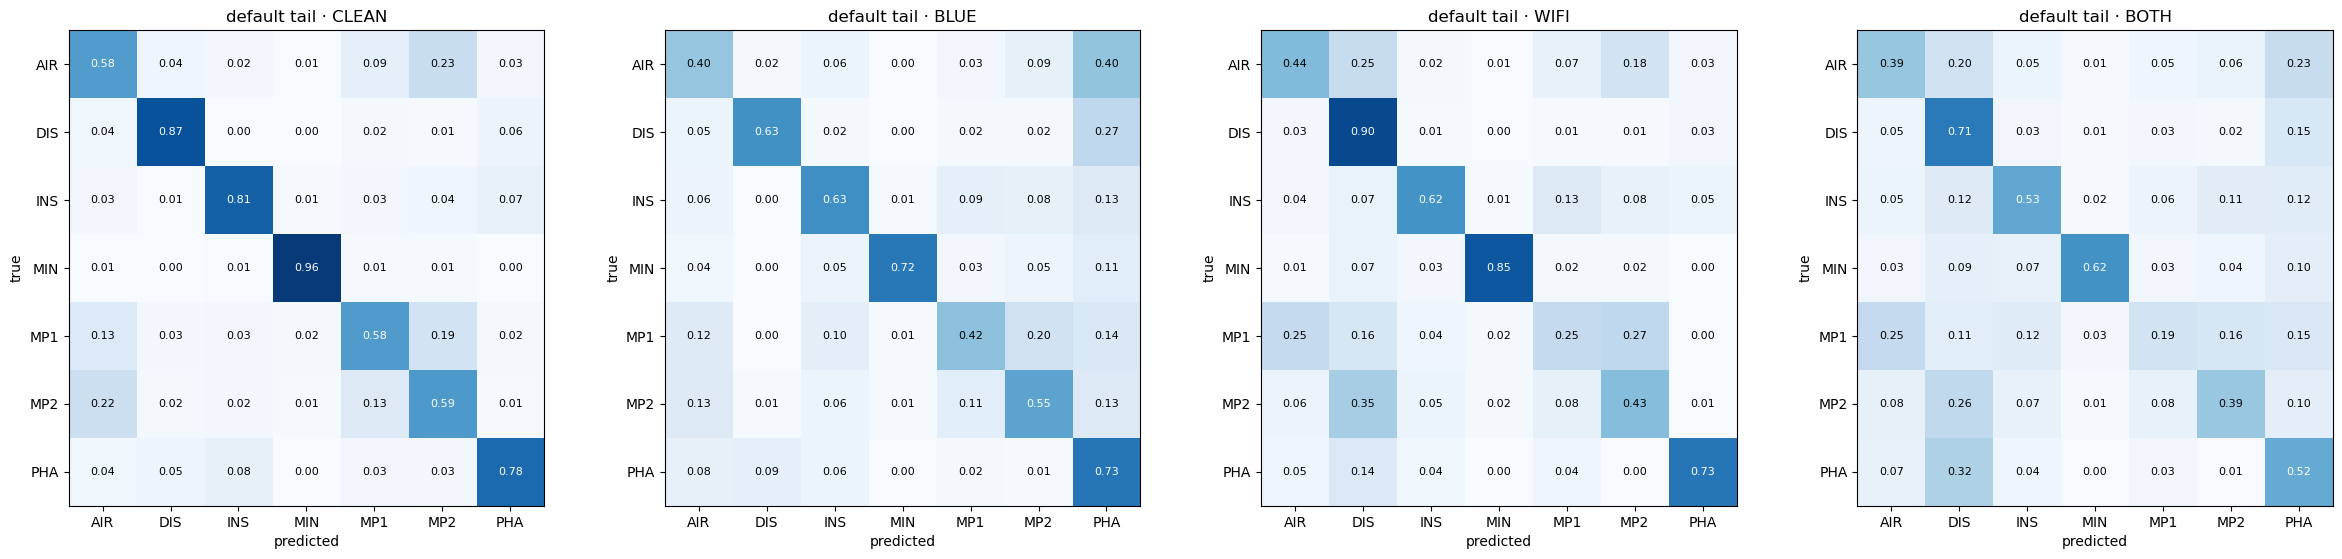

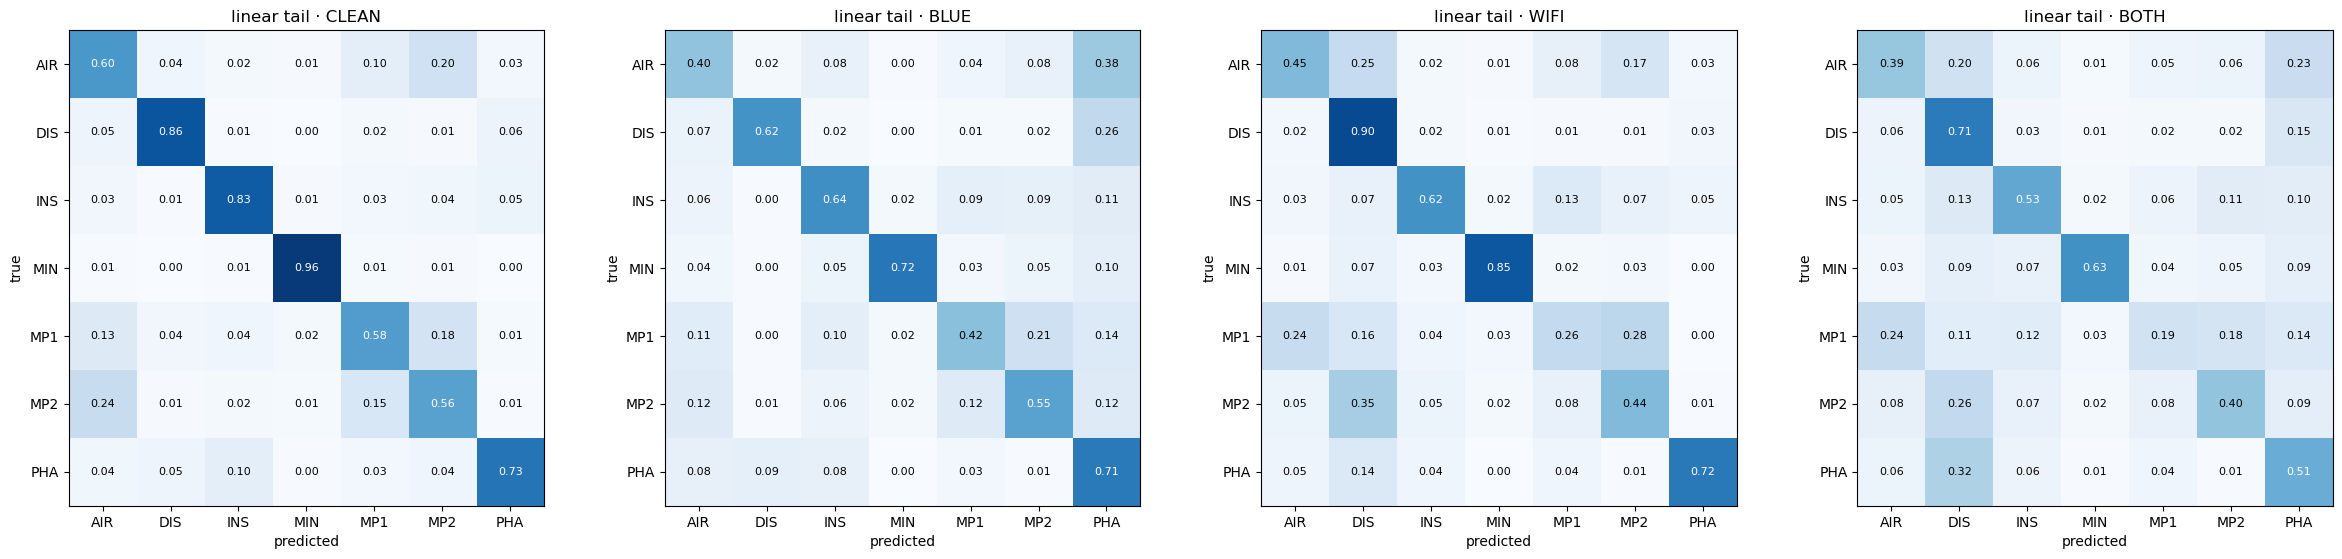

In [6]:
for tail in TAILS:
    fig, axes = plt.subplots(1, 4, figsize=(24, 5.5))
    for ax, sub in zip(axes, SUBSETS):
        cm = cms[(tail, sub)]; cmn = cm / cm.sum(1, keepdims=True)
        ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
        for i, j in itertools.product(range(len(CLASSES)), repeat=2):
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > 0.5 else "black")
        ax.set_xticks(range(len(CLASSES)), CLASSES); ax.set_yticks(range(len(CLASSES)), CLASSES)
        ax.set_title(f"{tail} tail · {sub}"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    plt.tight_layout(); fig.savefig(os.path.join(base, f"confusion_{tail}.png"), dpi=120, bbox_inches="tight"); plt.show()

## Energy-score separability and tail choice

AUROC for separating correct from wrong predictions, using the energy score `-logsumexp(z)` (lower = more confident) or max-softmax.
Rule: use the tail with the highest energy AUROC on the pooled interference subsets, unless its CLEAN macro-F1 is > 1 pp below the other tail's.

In [7]:
def auroc(correct, score):
    return roc_auc_score(correct, score) if 0 < correct.mean() < 1 else np.nan  # undefined if all right / all wrong


au = []
for tail, seed, fold in itertools.product(TAILS, SEEDS, range(K_FOLDS)):
    idx, z = load_run("active", tail, seed, fold)
    correct = z.argmax(1) == F["y"][idx]
    energy = -np.log(np.exp(z - z.max(1, keepdims=True)).sum(1)) - z.max(1)
    msp = softmax(z).max(1)
    sub = F["subset"][idx]
    for name, m in [(s, (sub == s) & F["seen"][idx]) for s in SUBSETS] + [("pooled_interference", (sub != "CLEAN") & F["seen"][idx])]:
        au.append({"tail": tail, "seed": seed, "fold": fold, "subset": name,
                   "energy_auroc": auroc(correct[m], -energy[m]), "msp_auroc": auroc(correct[m], msp[m])})
au = pd.DataFrame(au)
energy_auroc = pm(au, ["energy_auroc", "msp_auroc"], ["tail", "subset"])
energy_auroc.to_csv(os.path.join(base, "energy_auroc.csv"))

pooled = au[au.subset == "pooled_interference"].groupby("tail")["energy_auroc"].mean()
clean_f1 = runs[runs.subset == "CLEAN"].groupby("tail")["macro_f1"].mean()
best, other = pooled.idxmax(), pooled.idxmin()
CHOSEN_TAIL = best if clean_f1[best] >= clean_f1[other] - 0.01 else other
print("pooled energy AUROC:", pooled.round(4).to_dict(), "| CLEAN macro-F1:", clean_f1.round(4).to_dict())
print("CHOSEN TAIL:", CHOSEN_TAIL)
energy_auroc

pooled energy AUROC: {'default': 0.7232, 'linear': 0.7582} | CLEAN macro-F1: {'default': 0.733, 'linear': 0.7274}
CHOSEN TAIL: linear


energy_auroc        msp_auroc
tail    subset                                               
default BLUE                 0.7440 ± 0.0496  0.7944 ± 0.0256
        BOTH                 0.7053 ± 0.0420  0.7197 ± 0.0324
        CLEAN                0.7683 ± 0.0751  0.8777 ± 0.0274
        WIFI                 0.7182 ± 0.0452  0.7263 ± 0.0388
        pooled_interference  0.7232 ± 0.0392  0.7460 ± 0.0280
linear  BLUE                 0.8303 ± 0.0138  0.8194 ± 0.0128
        BOTH                 0.7265 ± 0.0325  0.7178 ± 0.0299
        CLEAN                0.8753 ± 0.0290  0.8820 ± 0.0297
        WIFI                 0.7194 ± 0.0463  0.7113 ± 0.0438
        pooled_interference  0.7582 ± 0.0287  0.7490 ± 0.0270

## Receiver-shortcut test (noise-only CLEAN windows)

Same CNN and protocol trained on windows at or below each recording's quiet floor. If these identify the drone well above
chance, the model can lean on the receiver configuration and noise floor rather than on the emissions. Group accuracy maps each
predicted drone to its receiver group (A: AIR/DIS/PHA, B: INS/MIN/MP1/MP2).

In [8]:
def shortcut(data, tail, suffix=""):
    sc = []
    g = np.array([GROUP[c] for c in CLASSES])
    for seed, fold in itertools.product(SEEDS, range(K_FOLDS)):
        idx, z = load_run(data, tail, seed, fold)
        y, pred = F["y"][idx], z.argmax(1)
        rep = classification_report_dict(y, pred, softmax(z), CLASSES)
        sc.append({"accuracy": rep["accuracy"], "group_accuracy": (g[y] == g[pred]).mean(),
                   **{f"{c}_recall": rep[f"{c}_recall"] for c in CLASSES}})
    sc = pd.DataFrame(sc)
    res = sc.agg(["mean", "std"]).T
    res["chance"] = [1 / 7, 1 / 2] + [np.nan] * len(CLASSES)
    res.to_csv(os.path.join(base, f"shortcut_test{suffix}.csv"))
    flagged = sc["accuracy"].mean() > 2 / 7
    print(f"{data}: noise-only 7-class accuracy {sc['accuracy'].mean():.3f} vs 2×chance {2/7:.3f} -> shortcut flagged: {flagged}")
    return res, flagged


shortcut_res, SHORTCUT = shortcut("noise", "default")
shortcut_res.round(4)

noise: noise-only 7-class accuracy 0.431 vs 2×chance 0.286 -> shortcut flagged: True


,mean,std,chance
accuracy,0.4311,0.0544,0.1429
group_accuracy,0.9772,0.0113,0.5000
AIR_recall,0.7052,0.1603,NaN
DIS_recall,0.4619,0.3046,NaN
INS_recall,0.4373,0.1222,NaN
MIN_recall,0.3139,0.1029,NaN
MP1_recall,0.3382,0.0743,NaN
MP2_recall,0.4980,0.1083,NaN
PHA_recall,0.2633,0.2069,NaN


## In-band mitigation (only if the shortcut test fired)

Keep only WPD nodes inside the 28 MHz receiver band (120-d input). Re-run the shortcut test (default tail, comparable with the
test above) and the main grid with the chosen tail, then compare both side by side.

In [9]:
if SHORTCUT:
    run_grid([("noise_inband", "default", s) for s in SEEDS] + [("active_inband", CHOSEN_TAIL, s) for s in SEEDS])
    shortcut_in, still = shortcut("noise_inband", "default", "_inband")
    runs_in, table_in, by_mode_in, cms_in = interference("active_inband", [CHOSEN_TAIL], "_inband")
    side = pd.concat({"full band": table.loc[CHOSEN_TAIL, ["accuracy", "macro_f1", "macro_f1_drop"]],
                      "in-band": table_in.loc[CHOSEN_TAIL, ["accuracy", "macro_f1", "macro_f1_drop"]]}, axis=1)
    side.to_csv(os.path.join(base, "inband_vs_fullband.csv"))
    display(pd.concat({"full band": shortcut_res.loc[["accuracy", "group_accuracy"], ["mean", "std"]],
                       "in-band": shortcut_in.loc[["accuracy", "group_accuracy"], ["mean", "std"]]}, axis=1).round(4))
    display(side)
else:
    print("No shortcut flagged: in-band mitigation not needed (task 6.2 skipped by rule).")

  0%|          | 0/10 [00:00<?, ?it/s]

 10%|█         | 1/10 [00:52<07:54, 52.77s/it]

 20%|██        | 2/10 [01:44<06:57, 52.13s/it]

 30%|███       | 3/10 [02:37<06:06, 52.35s/it]

 40%|████      | 4/10 [03:31<05:18, 53.05s/it]

...

100%|██████████| 10/10 [08:43<00:00, 52.33s/it]

noise_inband: noise-only 7-class accuracy 0.364 vs 2×chance 0.286 -> shortcut flagged: True


Unseen condition (Phantom 4 FY, not in CLEAN; 10000 rows per run), accuracy: {'linear': {'mean': 0.5135, 'std': 0.046}}


full band         in-band        
                    mean     std    mean     std
accuracy          0.4311  0.0544  0.3636  0.0356
group_accuracy    0.9772  0.0113  0.9627  0.0172

full band                                         in-band  \
               accuracy         macro_f1 macro_f1_drop         accuracy   
subset                                                                    
CLEAN   0.7310 ± 0.0463  0.7274 ± 0.0479           NaN  0.7044 ± 0.0506   
BLUE    0.5727 ± 0.0105  0.5829 ± 0.0105      0.144584  0.5075 ± 0.0154   
WIFI    0.5834 ± 0.0100  0.5876 ± 0.0122      0.139858  0.5341 ± 0.0106   
BOTH    0.4657 ± 0.0061  0.4618 ± 0.0076      0.265650  0.4129 ± 0.0050   

                                       
               macro_f1 macro_f1_drop  
subset                                 
CLEAN   0.7015 ± 0.0517           NaN  
BLUE    0.5300 ± 0.0157      0.171451  
WIFI    0.5361 ± 0.0126      0.165353  
BOTH    0.4140 ± 0.0060      0.287434